# Segmentación de clientes con K-Means
## Dataset *Online Retail*

En esta práctica prepararemos los datos de ventas y construiremos una tabla donde cada fila represente a un cliente. Después seleccionaremos **dos variables** para explorar la segmentación con K-Means.

**Pregunta guía:** ¿podemos distinguir perfiles de clientes considerando cuántas facturas realizaron y cuánto gastaron en total?

> La práctica se concentra en clientes identificados. Las ventas sin `CustomerID` no se pueden atribuir a un cliente, así que quedarán fuera del análisis de segmentación.

### Recorrido de la práctica

1. Cargar el CSV y reconocer sus columnas.
2. Revisar faltantes, duplicados, cancelaciones y valores no válidos.
3. Limpiar las transacciones que no representan compras identificables.
4. Calcular el importe por línea y resumir las compras por cliente.
5. Elegir dos variables y observar su distribución y correlación.
6. Aplicar `log1p`, normalización Min-Max y estandarización.
7. Explorar distintos valores de `k` con inercia y silhouette.
8. Ajustar K-Means e interpretar los grupos.

**Importante:** `CustomerID` identifica al cliente; no se usa como variable para medir distancias. Las variables del modelo serán `numero_facturas` y `gasto_total`.

## 1. Importar herramientas

Usaremos pandas y NumPy para preparar los datos, matplotlib y seaborn para las gráficas, y scikit-learn para transformar variables y aplicar K-Means.

Si hace falta instalar los paquetes desde la terminal: `python -m pip install pandas numpy matplotlib seaborn scikit-learn`.

In [8]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)

## 2. Cargar los datos

El notebook busca `online_retail.csv` en la misma carpeta y, como alternativa, en una subcarpeta `upload`. Si guardas el notebook en otra ubicación, coloca el CSV junto a él.

Leemos `InvoiceNo` y `StockCode` como texto porque son códigos, aunque algunos parezcan números. `CustomerID` se leerá con valores faltantes; lo convertiremos a entero después de excluir las filas que no tienen cliente identificado.

In [9]:
ruta_csv = Path("../data/raw/online_retail.csv")

datos_originales = pd.read_csv(
    ruta_csv,
    encoding="latin1",
    dtype={"InvoiceNo": "string", "StockCode": "string"}
)

datos = datos_originales.copy()

print("Archivo cargado:", ruta_csv)
print("Filas y columnas:", datos.shape)

Archivo cargado: ..\data\raw\online_retail.csv
Filas y columnas: (14832, 8)


## 3. Reconocer la estructura y revisar la calidad

Antes de limpiar, observamos algunas filas, los tipos de datos y los valores faltantes. Esto ayuda a decidir qué problemas afectan el análisis que queremos hacer.

In [10]:
display(datos.head())
print("\nTipos de datos y valores no nulos:")
datos.info()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



Tipos de datos y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 14832 entries, 0 to 14831
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    14832 non-null  string 
 1   StockCode    14832 non-null  string 
 2   Description  14772 non-null  str    
 3   Quantity     14832 non-null  int64  
 4   InvoiceDate  14832 non-null  str    
 5   UnitPrice    14831 non-null  float64
 6   CustomerID   10560 non-null  float64
 7   Country      14831 non-null  str    
dtypes: float64(2), int64(1), str(3), string(2)
memory usage: 927.1 KB


In [11]:
resumen_calidad = pd.DataFrame({
    "tipo de dato": datos.dtypes.astype(str),
    "valores faltantes": datos.isna().sum(),
    "valores distintos": datos.nunique(dropna=True)
})

display(resumen_calidad)
print("Filas duplicadas exactas:", datos.duplicated().sum())

,tipo de dato,valores faltantes,valores distintos
InvoiceNo,string,0,718
StockCode,string,0,2249
Description,str,60,2215
Quantity,int64,0,135
InvoiceDate,str,0,622
UnitPrice,float64,1,182
CustomerID,float64,4272,437
Country,str,1,15


Filas duplicadas exactas: 258


In [12]:
print("Transacciones con cantidad <= 0:", (datos["Quantity"] <= 0).sum())
print("Transacciones con precio <= 0:", (datos["UnitPrice"] <= 0).sum())
print("Facturas cuyo folio empieza con C:", datos["InvoiceNo"].str.startswith("C", na=False).sum())

Transacciones con cantidad <= 0: 222
Transacciones con precio <= 0: 124
Facturas cuyo folio empieza con C: 177


### ¿Qué problemas afectan esta segmentación?

- **Filas duplicadas exactas:** pueden repetir una misma línea de venta; las retiraremos una sola vez.
- **Cantidad negativa o cero:** en este dataset las cantidades negativas suelen representar devoluciones o cancelaciones; no describen una compra positiva.
- **Precio cero o negativo:** no aporta un importe de compra válido para el objetivo de esta práctica.
- **Factura con prefijo `C`:** identifica una factura cancelada; la excluiremos aunque el resto de sus valores parezca positivo.
- **`CustomerID` faltante:** no es posible asignar esa transacción a un cliente específico. Se excluirá del resumen por cliente.
- **Descripción faltante:** no la necesitamos porque el análisis usará facturas y gasto por cliente; por eso no eliminaremos una transacción solo por carecer de descripción.

Estas decisiones definen el alcance del análisis: estudiaremos compras positivas de clientes identificados.

## 4. Limpiar las transacciones paso a paso

### 4.1 Quitar duplicados exactos

`drop_duplicates()` conserva la primera aparición de cada fila completamente repetida. No elimina filas que solo comparten factura o producto, pero tienen otros valores diferentes.

In [13]:
filas_antes = len(datos)
datos_sin_duplicados = datos.drop_duplicates().copy()
print("Filas retiradas:", filas_antes - len(datos_sin_duplicados))
print("Filas restantes:", len(datos_sin_duplicados))

Filas retiradas: 258
Filas restantes: 14574


### 4.2 Convertir la fecha y hora

`InvoiceDate` llega como texto. La convertimos a tipo fecha y hora para que pandas pueda reconocerla. `errors="coerce"` convierte fechas inválidas en `NaT`, que luego podemos detectar y excluir.

In [14]:
datos_sin_duplicados["InvoiceDate"] = pd.to_datetime(
    datos_sin_duplicados["InvoiceDate"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

fechas_invalidas = datos_sin_duplicados["InvoiceDate"].isna().sum()
print("Fechas inválidas:", fechas_invalidas)

datos_con_fecha = datos_sin_duplicados.dropna(subset=["InvoiceDate"]).copy()
print("Filas con fecha válida:", len(datos_con_fecha))

Fechas inválidas: 1
Filas con fecha válida: 14573


### 4.3 Conservar transacciones con cliente identificado

El objetivo es formar un resumen por cliente. Sin `CustomerID`, no sabemos a qué cliente pertenece una venta; por eso esas filas no pueden participar en este análisis. Esta decisión no significa que sean ventas incorrectas: simplemente no sirven para segmentar clientes identificados.

In [15]:
filas_antes = len(datos_con_fecha)
datos_con_cliente = datos_con_fecha.dropna(subset=["CustomerID"]).copy()
datos_con_cliente["CustomerID"] = datos_con_cliente["CustomerID"].astype("int64")

print("Filas sin CustomerID excluidas:", filas_antes - len(datos_con_cliente))
print("Filas con cliente identificado:", len(datos_con_cliente))

Filas sin CustomerID excluidas: 4270
Filas con cliente identificado: 10303


### 4.4 Conservar compras válidas

Retenemos cantidades y precios positivos, y excluimos folios que comienzan con `C`. Separamos esta decisión de los pasos anteriores para que sea fácil observar cuántas filas elimina cada regla.

In [16]:
filas_antes = len(datos_con_cliente)

mascara_compra_valida = (
    (datos_con_cliente["Quantity"] > 0)
    & (datos_con_cliente["UnitPrice"] > 0)
    & (~datos_con_cliente["InvoiceNo"].str.startswith("C", na=False))
)

datos_limpios = datos_con_cliente.loc[mascara_compra_valida].copy()
print("Filas excluidas por reglas de compra válida:", filas_antes - len(datos_limpios))
print("Filas limpias:", len(datos_limpios))
print("Clientes identificados:", datos_limpios["CustomerID"].nunique())

display(datos_limpios.head())

Filas excluidas por reglas de compra válida: 152
Filas limpias: 10151
Clientes identificados: 408


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


### 4.5 Verificar el resultado de la limpieza

Comprobamos que las condiciones principales se cumplieron. La descripción puede seguir faltando: no es una variable que usaremos para agrupar clientes.

In [17]:
print("Valores faltantes por columna:")
display(datos_limpios.isna().sum().to_frame("faltantes"))

print("\nCantidad mínima:", datos_limpios["Quantity"].min())
print("Precio mínimo:", datos_limpios["UnitPrice"].min())
print("¿Quedan folios de cancelación?:", datos_limpios["InvoiceNo"].str.startswith("C", na=False).any())
print("¿Quedan filas duplicadas?:", datos_limpios.duplicated().sum())

Valores faltantes por columna:


,faltantes
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0



Cantidad mínima: 1
Precio mínimo: 0.07
¿Quedan folios de cancelación?: False
¿Quedan filas duplicadas?: 0


## 5. Crear variables de análisis por cliente

Cada fila de `datos_limpios` es una línea de factura, no un cliente. Para segmentar clientes, primero necesitamos resumir las transacciones.

Calcularemos:

- `importe_linea`: cantidad comprada multiplicada por el precio unitario.
- `numero_facturas`: cantidad de facturas distintas del cliente; representa frecuencia de compra dentro del periodo disponible.
- `gasto_total`: suma de los importes de sus líneas; representa el gasto acumulado registrado.

Usaremos estas dos últimas variables como coordenadas para K-Means.

In [18]:
datos_limpios["importe_linea"] = datos_limpios["Quantity"] * datos_limpios["UnitPrice"]

display(datos_limpios[["InvoiceNo", "CustomerID", "Quantity", "UnitPrice", "importe_linea"]].head())

,InvoiceNo,CustomerID,Quantity,UnitPrice,importe_linea
0,536365,17850,6,2.55,15.30
1,536365,17850,6,3.39,20.34
2,536365,17850,8,2.75,22.00
3,536365,17850,6,3.39,20.34
4,536365,17850,6,3.39,20.34


In [19]:
clientes = (
    datos_limpios
    .groupby("CustomerID")
    .agg(
        numero_facturas=("InvoiceNo", "nunique"),
        gasto_total=("importe_linea", "sum")
    )
    .reset_index()
)

display(clientes.head())
print("Clientes en la tabla resumida:", len(clientes))

,CustomerID,numero_facturas,gasto_total
0,12395,1,346.10
1,12427,1,303.50
2,12431,1,358.25
3,12433,1,1919.14
4,12472,1,1631.30


Clientes en la tabla resumida: 408


## 6. Seleccionar las dos variables y explorar su relación

Seleccionamos `numero_facturas` y `gasto_total` porque representan dos aspectos distintos del comportamiento de compra: frecuencia y monto acumulado. `CustomerID` se conserva para identificar y describir clientes, pero no se introduce al modelo porque es un código, no una medida de semejanza.

Primero observamos las distribuciones y los valores extremos. En datos de clientes, unos cuantos pueden comprar mucho más que la mayoría.

In [20]:
variables_modelo = ["numero_facturas", "gasto_total"]
X_original = clientes[variables_modelo].copy()

display(X_original.describe().round(2))

,numero_facturas,gasto_total
count,408.00,408.00
mean,1.34,495.84
std,1.82,868.63
min,1.00,5.20
25%,1.00,180.44
50%,1.00,303.45
75%,1.00,439.16
max,34.00,11429.50


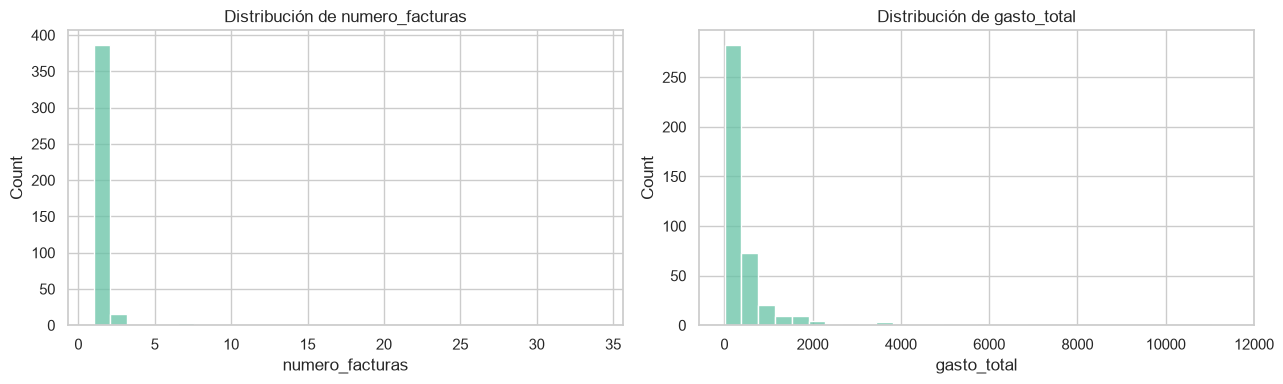

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, variable in zip(axes, variables_modelo):
    sns.histplot(data=X_original, x=variable, bins=30, ax=ax)
    ax.set_title(f"Distribución de {variable}")

plt.tight_layout()
plt.show()

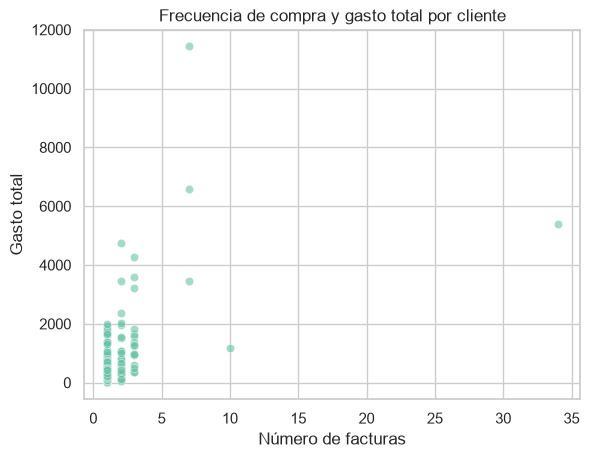

Correlación de Pearson en los valores originales:


,numero_facturas,gasto_total
numero_facturas,1.000,0.518
gasto_total,0.518,1.000


In [22]:
sns.scatterplot(data=X_original, x="numero_facturas", y="gasto_total", alpha=0.6)
plt.title("Frecuencia de compra y gasto total por cliente")
plt.xlabel("Número de facturas")
plt.ylabel("Gasto total")
plt.show()

print("Correlación de Pearson en los valores originales:")
display(X_original.corr().round(3))

La correlación describe si dos variables tienden a aumentar juntas o en dirección opuesta; no demuestra causalidad ni determina el número de grupos. La nube de puntos permite ver la forma de la relación.

En los histogramas también revisamos la asimetría. Si unos pocos clientes tienen valores muy altos, `log1p(x) = log(1 + x)` comprime esas diferencias sin borrar clientes ni cambiar el orden de sus valores. Como ambas variables son positivas, podemos aplicar la transformación.

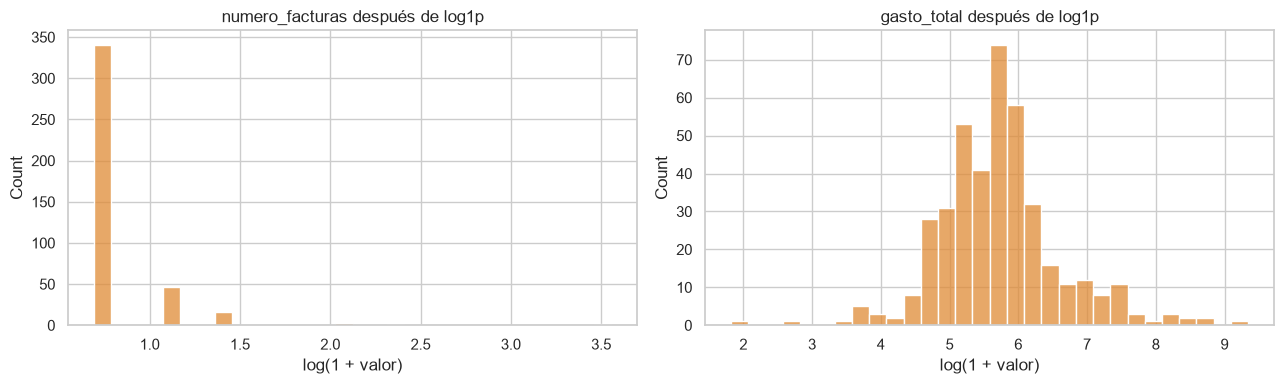

Correlación después de log1p:


,numero_facturas,gasto_total
numero_facturas,1.000,0.487
gasto_total,0.487,1.000


In [23]:
X_log = np.log1p(X_original)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, variable in zip(axes, variables_modelo):
    sns.histplot(data=X_log, x=variable, bins=30, ax=ax, color="#e08b36")
    ax.set_title(f"{variable} después de log1p")
    ax.set_xlabel("log(1 + valor)")

plt.tight_layout()
plt.show()

print("Correlación después de log1p:")
display(X_log.corr().round(3))

## 7. Normalización y estandarización

K-Means usa distancias. Si una variable tiene una escala numérica mucho mayor, puede pesar más en el cálculo. Por eso transformamos ambas variables.

En esta práctica distinguimos dos alternativas:

- **Normalización Min-Max:** lleva cada variable al intervalo de 0 a 1.
- **Estandarización:** centra cada variable cerca de 0 y la expresa en desviaciones estándar.

Para comparar las transformaciones, aplicamos cada una a los mismos datos que ya recibieron `log1p`. **No aplicaremos ambas una después de la otra**: son opciones de escalado. Para el modelo principal usaremos la matriz estandarizada.

In [24]:
normalizador = MinMaxScaler()
X_normalizado = pd.DataFrame(
    normalizador.fit_transform(X_log),
    columns=variables_modelo,
    index=clientes.index
)

estandarizador = StandardScaler()
X_estandarizado = pd.DataFrame(
    estandarizador.fit_transform(X_log),
    columns=variables_modelo,
    index=clientes.index
)

print("Ejemplo de valores normalizados entre 0 y 1:")
display(X_normalizado.head().round(3))

print("Ejemplo de valores estandarizados:")
display(X_estandarizado.head().round(3))

Ejemplo de valores normalizados entre 0 y 1:


,numero_facturas,gasto_total
0,0.0,0.535
1,0.0,0.518
2,0.0,0.540
3,0.0,0.763
4,0.0,0.741


Ejemplo de valores estandarizados:


,numero_facturas,gasto_total
0,-0.357,0.147
1,-0.357,-0.002
2,-0.357,0.185
3,-0.357,2.082
4,-0.357,1.898


In [25]:
print("Mínimos y máximos después de normalizar:")
display(X_normalizado.agg(["min", "max"]).round(3))

print("Promedio y desviación estándar después de estandarizar:")
display(pd.DataFrame({
    "promedio": X_estandarizado.mean(),
    "desviación estándar": X_estandarizado.std(ddof=0)
}).round(3))

Mínimos y máximos después de normalizar:


,numero_facturas,gasto_total
min,0.0,0.0
max,1.0,1.0


Promedio y desviación estándar después de estandarizar:


,promedio,desviación estándar
numero_facturas,0.0,1.0
gasto_total,-0.0,1.0


Para los pasos siguientes usaremos **`X_estandarizado`**. La decisión de escalado debe mantenerse igual al comparar diferentes valores de `k`; no mezcles resultados calculados con matrices distintas.

## 8. Explorar el número de grupos `k`

K-Means necesita que indiquemos cuántos grupos formar. Probaremos `k` de 2 a 8 con las mismas dos variables estandarizadas.

- **Inercia:** suma de las distancias al cuadrado de cada cliente a su centroide. Disminuye al añadir grupos; observamos dónde la reducción empieza a ser menor (el “codo”).
- **Silhouette:** compara qué tan cerca está cada cliente de su propio grupo frente al grupo vecino más cercano. Va de −1 a 1; valores mayores suelen señalar grupos mejor separados y compactos.

Ninguna métrica da por sí sola una respuesta universal. También revisaremos si los grupos tienen tamaños y perfiles interpretables.

In [26]:
resultados_k = []

for k in range(2, 9):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_estandarizado)

    resultados_k.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhouette": silhouette_score(X_estandarizado, etiquetas)
    })

metricas_k = pd.DataFrame(resultados_k)
display(metricas_k.round(3))

,k,inercia,silhouette
0,2,467.358,0.661
1,3,324.441,0.442
2,4,211.949,0.499
3,5,164.430,0.529
4,6,120.371,0.525
5,7,94.836,0.549
6,8,72.554,0.549


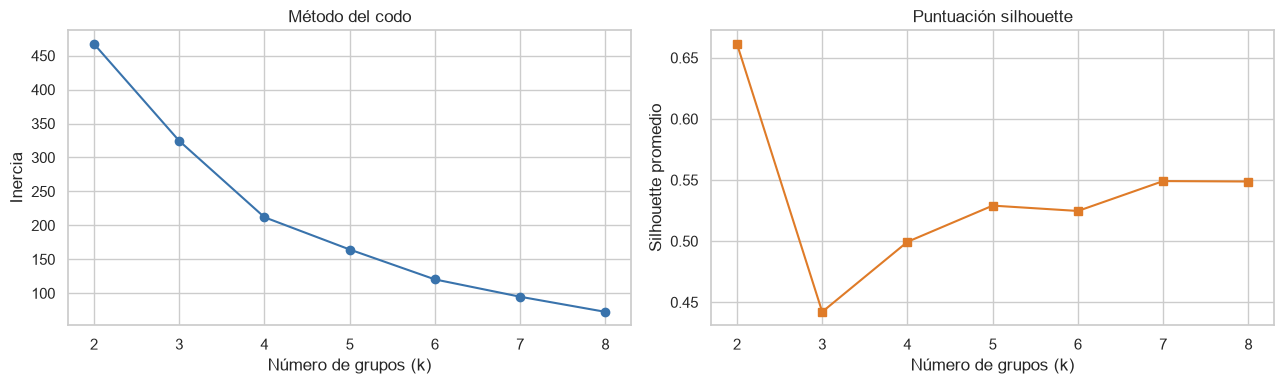

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(metricas_k["k"], metricas_k["inercia"], marker="o", color="#3973ac")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de grupos (k)")
axes[0].set_ylabel("Inercia")

axes[1].plot(metricas_k["k"], metricas_k["silhouette"], marker="s", color="#df7b28")
axes[1].set_title("Puntuación silhouette")
axes[1].set_xlabel("Número de grupos (k)")
axes[1].set_ylabel("Silhouette promedio")

plt.tight_layout()
plt.show()

### Cómo tomar una decisión

1. En la gráfica de inercia, busca un punto a partir del cual agregar grupos reduzca la inercia cada vez menos.
2. En silhouette, identifica los valores de `k` con puntuaciones relativamente altas.
3. Compara esos candidatos: ¿los grupos son suficientemente grandes y distintos para explicar perfiles de clientes?
4. Elige un valor justificable para el objetivo de la práctica. No selecciones automáticamente el `k` más alto ni interpretes las etiquetas como una escala.

Las métricas dependen de las variables y transformaciones usadas. Si cambias `X_estandarizado`, vuelve a calcularlas.

## 9. Ajustar K-Means e interpretar los grupos

Como punto de partida usaremos `k = 2`, que en esta preparación suele destacar en silhouette. Revisa la tabla anterior y cambia el valor si la curva de inercia, la interpretación de los perfiles o el objetivo de la clase justifican otra elección.

Las etiquetas `0`, `1`, etc. son nombres asignados por el algoritmo; no representan un orden de mejor a peor.

In [28]:
k_elegido = 2

modelo_kmeans = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
clientes["Cluster"] = modelo_kmeans.fit_predict(X_estandarizado)

conteo_grupos = clientes["Cluster"].value_counts().sort_index().to_frame("clientes")
conteo_grupos["porcentaje"] = (conteo_grupos["clientes"] / len(clientes) * 100).round(1)
display(conteo_grupos)

,clientes,porcentaje
Cluster,,
0,373,91.4
1,35,8.6


In [29]:
perfil_grupos = (
    clientes
    .groupby("Cluster")
    .agg(
        clientes=("CustomerID", "size"),
        facturas_mediana=("numero_facturas", "median"),
        gasto_mediano=("gasto_total", "median"),
        facturas_promedio=("numero_facturas", "mean"),
        gasto_promedio=("gasto_total", "mean")
    )
    .round(2)
)

display(perfil_grupos)

,clientes,facturas_mediana,gasto_mediano,facturas_promedio,gasto_promedio
Cluster,,,,,
0,373,1.0,283.15,1.09,337.30
1,35,3.0,1389.12,4.03,2185.41


La mediana ayuda a describir al cliente típico de cada grupo y suele ser menos sensible que el promedio a clientes con gastos extremadamente altos. Compara las medianas de facturas y gasto para poner nombres descriptivos a los perfiles, por ejemplo, frecuencia y gasto más bajos o más altos. Basa esos nombres en los valores observados.

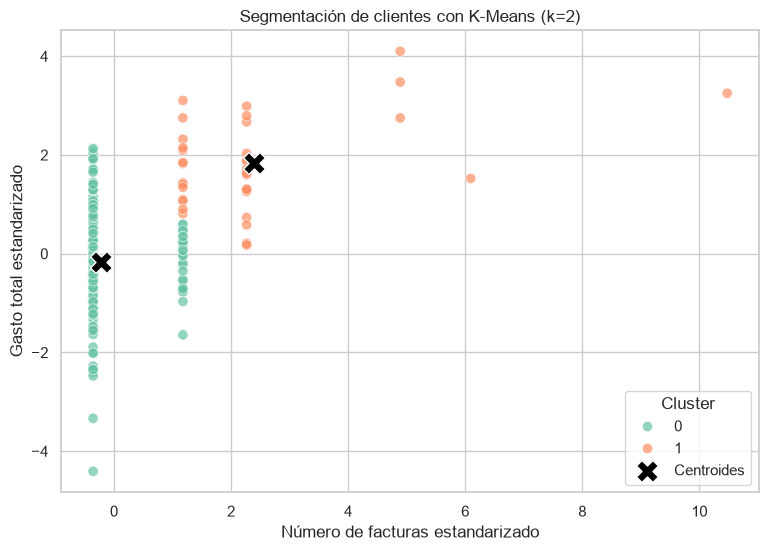

In [30]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_estandarizado["numero_facturas"],
    y=X_estandarizado["gasto_total"],
    hue=clientes["Cluster"].astype(str),
    palette="Set2",
    alpha=0.7,
    s=55
)

centroides = modelo_kmeans.cluster_centers_
plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    marker="X",
    s=250,
    color="black",
    edgecolor="white",
    label="Centroides"
)

plt.title(f"Segmentación de clientes con K-Means (k={k_elegido})")
plt.xlabel("Número de facturas estandarizado")
plt.ylabel("Gasto total estandarizado")
plt.legend(title="Cluster")
plt.show()

## 10. Resumen y preguntas de análisis

| Etapa | Qué hicimos | Para qué |
|---|---|---|
| Calidad | Revisamos faltantes, duplicados, fechas, cantidades, precios y cancelaciones | Entender qué datos requieren tratamiento |
| Limpieza | Conservamos compras positivas con cliente identificado | Delimitar qué transacciones podemos atribuir a un cliente |
| Agregación | Resumimos líneas por `CustomerID` | Convertir transacciones en perfiles de cliente |
| Variables | Usamos número de facturas y gasto total | Representar frecuencia y monto de compra |
| Transformación | Aplicamos `log1p` | Reducir asimetría sin eliminar clientes extremos |
| Escalado | Comparamos Min-Max y estandarización; usamos estandarización | Evitar que la escala de una variable domine la distancia |
| Agrupamiento | Comparamos `k` y ajustamos K-Means | Proponer segmentos y describir sus perfiles |

### Preguntas para discutir

1. ¿Por qué no usamos `CustomerID` como coordenada para agrupar?
2. ¿Qué significa que excluyamos transacciones sin cliente identificado?
3. ¿Por qué agrupamos por cliente antes de aplicar K-Means?
4. ¿Qué diferencia hay entre normalizar con Min-Max y estandarizar?
5. ¿Qué indicios aportan la inercia y silhouette al elegir `k`?
6. ¿Qué comportamiento distingue a cada grupo según las medianas?
7. ¿Qué información perdemos al resumir todas las compras de un cliente en dos variables?